<a href="https://colab.research.google.com/github/reshmiee/codemixing_llmrouter/blob/main/person4_RouteLLM_Benchmark_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pandas numpy scikit-learn scipy joblib

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/ResearchPaper(ML)"

print(os.listdir(BASE))

Mounted at /content/drive
['data', 'dataset', '_dryrun', 'features', 'results', 'scores', 'report', 'models', 'correction_model_results', 'reproduce_correction_models.py', 'correction_model_results_reproduced']


In [3]:
for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/drive/MyDrive/ResearchPaper(ML)/data/confirmatory_v1.csv
/content/drive/MyDrive/ResearchPaper(ML)/data/ood_scrambled_texts_v1.csv
/content/drive/MyDrive/ResearchPaper(ML)/data/gsm8k_english_100.csv
/content/drive/MyDrive/ResearchPaper(ML)/dataset/confirmatoryv1_clean.csv
/content/drive/MyDrive/ResearchPaper(ML)/_dryrun/scores/scores_confirmatory_v1.csv
/content/drive/MyDrive/ResearchPaper(ML)/_dryrun/scores/scores_ood_scrambled_v1.csv
/content/drive/MyDrive/ResearchPaper(ML)/_dryrun/results/person3/p3_ridge_vif_v1.csv
/content/drive/MyDrive/ResearchPaper(ML)/_dryrun/results/person3/p3_two_way_anova_v1.csv
/content/drive/MyDrive/ResearchPaper(ML)/_dryrun/results/person3/p3_by_difficulty_v1.csv
/content/drive/MyDrive/ResearchPaper(ML)/_dryrun/results/person3/p3_by_written_by_v1.csv
/content/drive/MyDrive/ResearchPaper(ML)/_dryrun/results/person3/p3_by_task_type_v1.csv
/content/drive/MyDrive/ResearchPaper(ML)/_dryrun/results/person3/p3_main_result_v1.csv
/content/drive/MyDrive/Re

In [4]:
import pandas as pd
import os

files_to_check = [
    "scores/scores_v1.csv",
    "scores/scores_v2.csv",
    "scores/scores_confirmatory_v1.csv",
    "features/features_v1.csv",
    "features/features_v2.csv",
    "features/features_v3.csv",
    "features/p3_features_v1.csv",
    "features/features_confirmatory_v1.csv"
]

for file in files_to_check:
    path = os.path.join(BASE, file)
    df = pd.read_csv(path)

    print("\nFILE:", file)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(2))


FILE: scores/scores_v1.csv
Shape: (80, 4)
Columns: ['pair_id', 'english_score', 'hinglish_score', 'diff_en_minus_hi']


,pair_id,english_score,hinglish_score,diff_en_minus_hi
0,1,0.249989,0.280707,-0.030718
1,2,0.205350,0.336730,-0.131379



FILE: scores/scores_v2.csv
Shape: (80, 4)
Columns: ['pair_id', 'english_score', 'hinglish_score', 'diff_en_minus_hi']


,pair_id,english_score,hinglish_score,diff_en_minus_hi
0,1,0.249989,0.280707,-0.030718
1,2,0.205350,0.336730,-0.131379



FILE: scores/scores_confirmatory_v1.csv
Shape: (152, 7)
Columns: ['pair_id', 'english_score', 'hinglish_score', 'diff_en_minus_hi', 'task_type', 'difficulty', 'written_by']


,pair_id,english_score,hinglish_score,diff_en_minus_hi,task_type,difficulty,written_by
0,101,0.593834,0.536935,0.056899,Coding,Easy,A
1,102,0.485699,0.494614,-0.008915,Coding,Easy,A


... (6 outputs left out)


FILE: features/p3_features_v1.csv
Shape: (80, 13)
Columns: ['pair_id', 'en_tokens', 'en_words', 'en_fertility', 'en_rare', 'hi_tokens', 'hi_words', 'hi_fertility', 'hi_rare', 'd_tokens', 'd_words', 'd_fertility', 'd_rare']


,pair_id,en_tokens,en_words,en_fertility,en_rare,hi_tokens,hi_words,hi_fertility,hi_rare,d_tokens,d_words,d_fertility,d_rare
0,1,14,10,1.400000,0,13,9,1.444444,0,1,1,-0.044444,0
1,2,10,9,1.111111,0,9,8,1.125000,0,1,1,-0.013889,0



FILE: features/features_confirmatory_v1.csv
Shape: (152, 10)
Columns: ['pair_id', 'english_words', 'english_tokens', 'english_fertility', 'hinglish_words', 'hinglish_tokens', 'hinglish_fertility', 'tokens_diff_en_minus_hi', 'words_diff_en_minus_hi', 'fert_diff_en_minus_hi']


,pair_id,english_words,english_tokens,english_fertility,hinglish_words,hinglish_tokens,hinglish_fertility,tokens_diff_en_minus_hi,words_diff_en_minus_hi,fert_diff_en_minus_hi
0,101,21,41,1.952381,29,49,1.689655,-8,-8,0.262726
1,102,14,28,2.000000,16,29,1.812500,-1,-2,0.187500


In [5]:
for file in files_to_check:
    path = os.path.join(BASE, file)
    df = pd.read_csv(path)

    print("\n", file)

    for col in df.columns:
        if col.lower() in ["id", "pair_id", "question_id"]:
            print("ID column:", col)
            print("First IDs:", df[col].head(5).tolist())
            print("Last IDs:", df[col].tail(5).tolist())


 scores/scores_v1.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 scores/scores_v2.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 scores/scores_confirmatory_v1.csv
ID column: pair_id
First IDs: [101, 102, 103, 104, 105]
Last IDs: [248, 249, 250, 251, 252]

 features/features_v1.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 features/features_v2.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 features/features_v3.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 features/p3_features_v1.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 features/features_confirmatory_v1.csv
ID column: pair_id
First IDs: [101, 102, 103, 104, 105]
Last IDs: [248, 249, 250, 251, 252]


In [7]:
pilot_scores = pd.read_csv(BASE + "/scores/scores_v2.csv")
pilot_features = pd.read_csv(BASE + "/features/features_v2.csv")

test_scores = pd.read_csv(BASE + "/scores/scores_confirmatory_v1.csv")
test_features = pd.read_csv(BASE + "/features/features_confirmatory_v1.csv")

print("Pilot scores:", pilot_scores.shape)
print("Pilot features:", pilot_features.shape)
print("Test scores:", test_scores.shape)
print("Test features:", test_features.shape)

Pilot scores: (80, 4)
Pilot features: (80, 8)
Test scores: (152, 7)
Test features: (152, 10)


In [8]:
ID_COL = "pair_id"

EN_SCORE = "english_score"
HI_SCORE = "hinglish_score"

PILOT_FEATURE_COLS = ["hi_tokens", "hi_words", "hi_fertility"]
TEST_FEATURE_COLS = [
    "hinglish_tokens",
    "hinglish_words",
    "hinglish_fertility"
]

In [9]:
pilot_features = pilot_features.rename(columns={
    "hi_tokens": "hinglish_tokens",
    "hi_words": "hinglish_words",
    "hi_fertility": "hinglish_fertility"
})

FEATURE_COLS = [
    "hinglish_tokens",
    "hinglish_words",
    "hinglish_fertility"
]

In [10]:
pilot = pilot_scores.merge(
    pilot_features[[ID_COL] + FEATURE_COLS],
    on=ID_COL,
    how="inner",
    validate="one_to_one"
)

test = test_scores.merge(
    test_features[[ID_COL] + FEATURE_COLS],
    on=ID_COL,
    how="inner",
    validate="one_to_one"
)

print("Training pairs:", len(pilot))
print("Testing pairs:", len(test))

display(pilot.head())
display(test.head())

Training pairs: 80
Testing pairs: 152


,pair_id,english_score,hinglish_score,diff_en_minus_hi,hinglish_tokens,hinglish_words,hinglish_fertility
0,1,0.249989,0.280707,-0.030718,13,9,1.444444
1,2,0.205350,0.336730,-0.131379,9,8,1.125000
2,3,0.467379,0.443534,0.023845,18,13,1.384615
3,4,0.282970,0.412477,-0.129507,12,10,1.200000
4,5,0.234917,0.288684,-0.053767,13,10,1.300000


,pair_id,english_score,hinglish_score,diff_en_minus_hi,task_type,difficulty,written_by,hinglish_tokens,hinglish_words,hinglish_fertility
0,101,0.593834,0.536935,0.056899,Coding,Easy,A,49,29,1.689655
1,102,0.485699,0.494614,-0.008915,Coding,Easy,A,29,16,1.812500
2,103,0.532111,0.503105,0.029006,Coding,Easy,A,44,26,1.692308
3,104,0.496512,0.507816,-0.011304,Coding,Easy,A,37,19,1.947368
4,105,0.521810,0.519925,0.001885,Coding,Easy,A,41,21,1.952381


In [11]:
assert len(pilot) == 80, "Pilot dataset should contain 80 pairs"
assert len(test) == 152, "Test dataset should contain 152 pairs"

assert not pilot.duplicated(ID_COL).any()
assert not test.duplicated(ID_COL).any()

assert pilot[FEATURE_COLS + [EN_SCORE, HI_SCORE]].notna().all().all()
assert test[FEATURE_COLS + [EN_SCORE, HI_SCORE]].notna().all().all()

print("Data validation successful.")

Data validation successful.


In [12]:
from sklearn.preprocessing import StandardScaler

X_train = pilot[[HI_SCORE] + FEATURE_COLS]
y_train = pilot[EN_SCORE]

X_test = test[[HI_SCORE] + FEATURE_COLS]
y_test = test[EN_SCORE]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

gb_model = GradientBoostingRegressor(
    n_estimators=30,
    learning_rate=0.03,
    max_depth=1,
    random_state=42
)

gb_model.fit(X_train_scaled, y_train)

print("Both correction models trained.")

Both correction models trained.


In [14]:
original_scores = test[HI_SCORE].values

constant_scores = np.full(len(test), y_train.mean())

linear_scores = linear_model.predict(X_test_scaled)

orthogonal_scores = (
    (original_scores - pilot[HI_SCORE].mean())
    * (pilot[EN_SCORE].std() / pilot[HI_SCORE].std())
    + pilot[EN_SCORE].mean()
)

gb_scores = gb_model.predict(X_test_scaled)

predictions = {
    "Original RouteLLM": original_scores,
    "Constant Baseline": constant_scores,
    "Linear (score + token features)": np.clip(linear_scores, 0, 1),
    "Orthogonal Rescaling": np.clip(orthogonal_scores, 0, 1),
    "Gradient Boosting": np.clip(gb_scores, 0, 1)
}

In [15]:
from sklearn.linear_model import LinearRegression

pilot_v2 = pd.read_csv(BASE + "/scores/scores_v2.csv")

uni = LinearRegression().fit(
    pilot_v2[["hinglish_score"]].values,
    pilot_v2["english_score"].values
)

uni_scores = np.clip(uni.predict(test[[HI_SCORE]].values), 0, 1)
predictions["Linear (univariate)"] = uni_scores

print("intercept, slope:", uni.intercept_, uni.coef_[0])

intercept, slope: -0.29572560090499533 1.586522660237617


In [16]:
from sklearn.metrics import mean_absolute_error, cohen_kappa_score

thresholds = {
    "10%": 0.5949,
    "20%": 0.5094,
    "30%": 0.4651,
    "50%": 0.4066,
    "70%": 0.3372
}

results = []

for model_name, scores in predictions.items():
    row = {
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, scores),
        "English SD": np.std(y_test, ddof=1),
        "Corrected SD": np.std(scores, ddof=1),
        "SD Ratio": np.std(y_test, ddof=1) / np.std(scores, ddof=1)
    }

    for threshold_name, threshold in thresholds.items():
        english_route = (y_test >= threshold).astype(int)
        predicted_route = (scores >= threshold).astype(int)

        row[f"{threshold_name} Agreement"] = np.mean(
            english_route == predicted_route
        )

        row[f"{threshold_name} Kappa"] = cohen_kappa_score(
            english_route, predicted_route
        )

    results.append(row)

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,MAE,English SD,Corrected SD,SD Ratio,10% Agreement,10% Kappa,20% Agreement,20% Kappa,30% Agreement,30% Kappa,50% Agreement,50% Kappa,70% Agreement,70% Kappa
0,Original RouteLLM,0.0804,0.1723,0.0892,1.930300e+00,0.8355,0.2765,0.7697,0.5015,0.8947,0.7898,0.8684,0.7154,0.8684,0.6053
1,Constant Baseline,0.1501,0.1723,0.0000,3.093128e+15,0.7961,0.0000,0.5724,0.0000,0.4737,0.0000,0.5987,0.0000,0.7303,0.0000
2,Linear (score + token features),0.0769,0.1723,0.1425,1.208800e+00,0.8487,0.3564,0.7632,0.4862,0.8224,0.6498,0.9079,0.8114,0.8882,0.7183
3,Orthogonal Rescaling,0.0728,0.1723,0.1601,1.076100e+00,0.8750,0.5164,0.7895,0.5507,0.8882,0.7774,0.8947,0.7821,0.8947,0.7446
4,Gradient Boosting,0.1001,0.1723,0.0655,2.631200e+00,0.7961,0.0000,0.5724,0.0000,0.9013,0.8033,0.8947,0.7798,0.9013,0.7309
5,Linear (univariate),0.0719,0.1723,0.1416,1.216700e+00,0.8487,0.3564,0.7697,0.5035,0.8618,0.7258,0.8947,0.7821,0.9079,0.7697


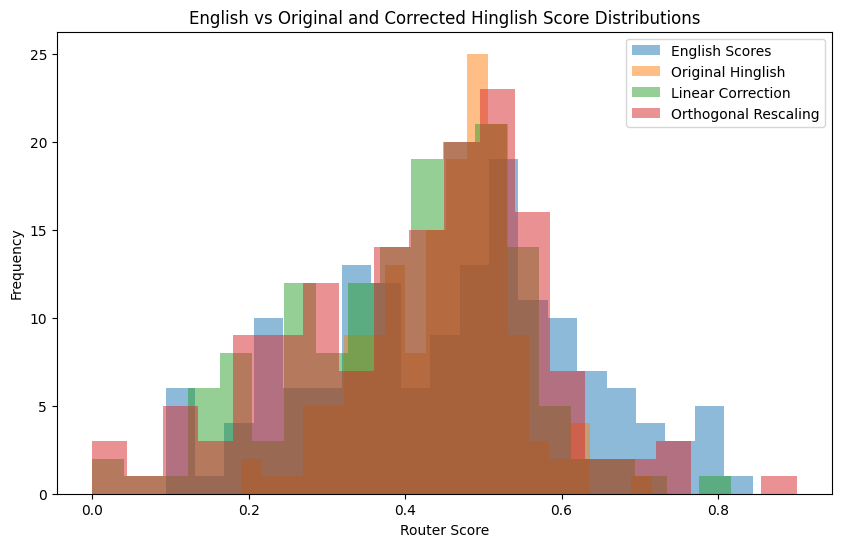

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(y_test, bins=20, alpha=0.5, label="English Scores")
plt.hist(original_scores, bins=20, alpha=0.5, label="Original Hinglish")
plt.hist(predictions["Linear (score + token features)"], bins=20, alpha=0.5, label="Linear Correction")
plt.hist(predictions["Orthogonal Rescaling"], bins=20, alpha=0.5, label="Orthogonal Rescaling")

plt.xlabel("Router Score")
plt.ylabel("Frequency")
plt.title("English vs Original and Corrected Hinglish Score Distributions")
plt.legend()
plt.show()

In [20]:
OUTPUT_DIR = BASE + "/correction_model_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

results_df.to_csv(
    OUTPUT_DIR + "/model_comparison_v1.csv",
    index=False
)

corrected_df = test[[ID_COL, EN_SCORE, HI_SCORE]].copy()

for name, scores in predictions.items():
    corrected_df[name] = scores

corrected_df.to_csv(
    OUTPUT_DIR + "/corrected_scores_v1.csv",
    index=False
)

print("Results saved to:", OUTPUT_DIR)

Results saved to: /content/drive/MyDrive/ResearchPaper(ML)/correction_model_results


In [22]:
from sklearn.metrics import mean_absolute_error, cohen_kappa_score

difficulty_results = []

for difficulty in test["difficulty"].unique():
    mask = test["difficulty"] == difficulty

    english = test.loc[mask, EN_SCORE].values

    for model_name in [
        "Original RouteLLM",
        "Linear (score + token features)",
        "Orthogonal Rescaling"
    ]:
        scores = predictions[model_name][mask.values]

        english_route = (english >= 0.4066).astype(int)
        predicted_route = (scores >= 0.4066).astype(int)

        difficulty_results.append({
            "Difficulty": difficulty,
            "Model": model_name,
            "Pairs": len(english),
            "MAE": mean_absolute_error(english, scores),
            "50% Agreement": np.mean(english_route == predicted_route),
            "50% Kappa": cohen_kappa_score(
                english_route, predicted_route
            )
        })

difficulty_df = pd.DataFrame(difficulty_results)

display(
    difficulty_df.round(4).sort_values(
        ["Difficulty", "Model"]
    )
)

,Difficulty,Model,Pairs,MAE,50% Agreement,50% Kappa
1,Easy,Linear (score + token features),76,0.0888,0.9211,0.8421
0,Easy,Original RouteLLM,76,0.0930,0.8289,0.6579
2,Easy,Orthogonal Rescaling,76,0.0813,0.8947,0.7895
4,Hard,Linear (score + token features),76,0.0651,0.8947,0.7623
3,Hard,Original RouteLLM,76,0.0679,0.9079,0.7734
5,Hard,Orthogonal Rescaling,76,0.0644,0.8947,0.7678


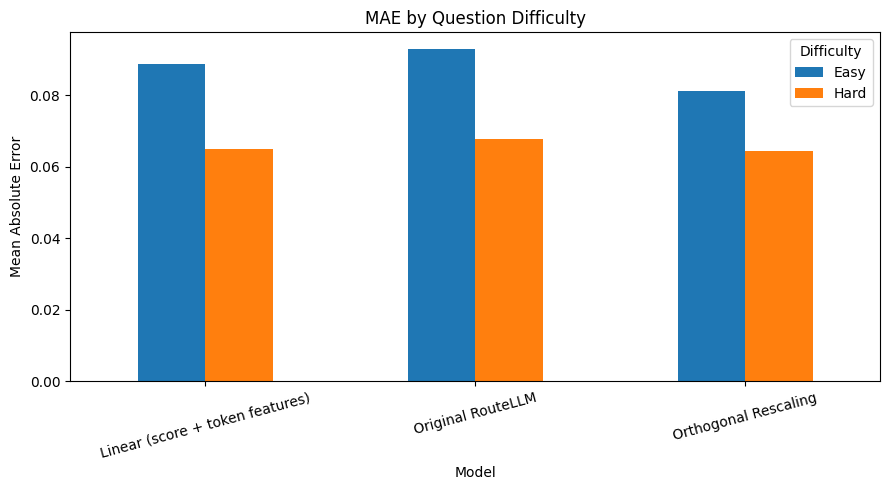

In [23]:
difficulty_pivot = difficulty_df.pivot(
    index="Model",
    columns="Difficulty",
    values="MAE"
)

difficulty_pivot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("MAE by Question Difficulty")
plt.ylabel("Mean Absolute Error")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.legend(title="Difficulty")
plt.tight_layout()
plt.show()

In [24]:
rng = np.random.default_rng(0)

def boot_improvement(original, corrected, n=10000):
    english = y_test.to_numpy()
    original = np.asarray(original)
    corrected = np.asarray(corrected)

    # Positive values mean the correction improves on the original.
    differences = (
        np.abs(english - original)
        - np.abs(english - corrected)
    )

    indices = rng.integers(
        0, len(differences), size=(n, len(differences))
    )
    bootstrap_means = differences[indices].mean(axis=1)

    return (
        differences.mean(),
        np.percentile(bootstrap_means, 2.5),
        np.percentile(bootstrap_means, 97.5)
    )

for name, scores in predictions.items():
    if name == "Original RouteLLM":
        continue

    improvement, lower, upper = boot_improvement(
        predictions["Original RouteLLM"], scores
    )

    print(f"\n{name}")
    print(f"MAE improvement: {improvement:.4f}")
    print(f"95% CI: [{lower:.4f}, {upper:.4f}]")


Constant Baseline
MAE improvement: -0.0696
95% CI: [-0.0796, -0.0600]

Linear (score + token features)
MAE improvement: 0.0035
95% CI: [-0.0056, 0.0124]

Orthogonal Rescaling
MAE improvement: 0.0076
95% CI: [-0.0008, 0.0159]

Gradient Boosting
MAE improvement: -0.0196
95% CI: [-0.0271, -0.0127]

Linear (univariate)
MAE improvement: 0.0085
95% CI: [0.0014, 0.0155]


In [25]:
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

route_results = []

for model_name, scores in predictions.items():
    raw_p_values = []

    for threshold_name, threshold in thresholds.items():
        english_route = (y_test.to_numpy() >= threshold)
        hinglish_route = (np.asarray(scores) >= threshold)

        english_only_strong = np.sum(english_route & ~hinglish_route)
        hinglish_only_strong = np.sum(~english_route & hinglish_route)

        both_strong = np.sum(english_route & hinglish_route)
        both_weak = np.sum(~english_route & ~hinglish_route)

        table = [
            [both_strong, english_only_strong],
            [hinglish_only_strong, both_weak]
        ]

        p_value = mcnemar(table, exact=True).pvalue
        raw_p_values.append(p_value)

        route_results.append({
            "Model": model_name,
            "Threshold": threshold_name,
            "English-only strong": english_only_strong,
            "Hinglish-only strong": hinglish_only_strong,
            "McNemar p": p_value
        })

route_results_df = pd.DataFrame(route_results)

route_results_df["Holm-adjusted p"] = (
    route_results_df.groupby("Model")["McNemar p"]
    .transform(lambda p: multipletests(p, method="holm")[1])
)

display(route_results_df.round(4))

,Model,Threshold,English-only strong,Hinglish-only strong,McNemar p,Holm-adjusted p
0,Original RouteLLM,10%,25,0,0.0000,0.0000
1,Original RouteLLM,20%,32,3,0.0000,0.0000
2,Original RouteLLM,30%,11,5,0.2101,0.2101
3,Original RouteLLM,50%,3,17,0.0026,0.0052
4,Original RouteLLM,70%,0,20,0.0000,0.0000
5,Constant Baseline,10%,31,0,0.0000,0.0000
6,Constant Baseline,20%,65,0,0.0000,0.0000
7,Constant Baseline,30%,80,0,0.0000,0.0000
8,Constant Baseline,50%,0,61,0.0000,0.0000
9,Constant Baseline,70%,0,41,0.0000,0.0000


In [26]:
OUTPUT_DIR = BASE + "/correction_model_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

results_df.to_csv(
    OUTPUT_DIR + "/model_comparison_v2.csv",
    index=False
)

corrected_df = test[[ID_COL, EN_SCORE, HI_SCORE]].copy()
for name, scores in predictions.items():
    corrected_df[name] = scores

corrected_df.to_csv(
    OUTPUT_DIR + "/corrected_scores_v2.csv",
    index=False
)

route_results_df.to_csv(
    OUTPUT_DIR + "/mcnemar_holm_v2.csv",
    index=False
)

print("Saved Step 1 results to:", OUTPUT_DIR)

Saved Step 1 results to: /content/drive/MyDrive/ResearchPaper(ML)/correction_model_results


In [27]:
%%writefile /content/drive/MyDrive/ResearchPaper(ML)/reproduce_correction_models.py
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, cohen_kappa_score
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

BASE = Path(__file__).resolve().parent
OUTPUT_DIR = BASE / "correction_model_results_reproduced"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ID_COL = "pair_id"
EN_SCORE = "english_score"
HI_SCORE = "hinglish_score"
FEATURE_COLS = [
    "hinglish_tokens",
    "hinglish_words",
    "hinglish_fertility"
]

# Load the existing score and feature files. This script does not rescore prompts.
pilot_scores = pd.read_csv(BASE / "scores" / "scores_v2.csv")
pilot_features = pd.read_csv(BASE / "features" / "features_v2.csv")
test_scores = pd.read_csv(BASE / "scores" / "scores_confirmatory_v1.csv")
test_features = pd.read_csv(BASE / "features" / "features_confirmatory_v1.csv")

pilot_features = pilot_features.rename(columns={
    "hi_tokens": "hinglish_tokens",
    "hi_words": "hinglish_words",
    "hi_fertility": "hinglish_fertility"
})

pilot = pilot_scores.merge(
    pilot_features[[ID_COL] + FEATURE_COLS],
    on=ID_COL,
    how="inner",
    validate="one_to_one"
)
test = test_scores.merge(
    test_features[[ID_COL] + FEATURE_COLS],
    on=ID_COL,
    how="inner",
    validate="one_to_one"
)

assert len(pilot) == 80, f"Expected 80 pilot pairs, found {len(pilot)}"
assert len(test) == 152, f"Expected 152 confirmatory pairs, found {len(test)}"

# Fit correction models on the pilot set.
X_train = pilot[[HI_SCORE] + FEATURE_COLS]
y_train = pilot[EN_SCORE]
X_test = test[[HI_SCORE] + FEATURE_COLS]
y_test = test[EN_SCORE]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

multi_model = LinearRegression().fit(X_train_scaled, y_train)
gb_model = GradientBoostingRegressor(
    n_estimators=30,
    learning_rate=0.03,
    max_depth=1,
    random_state=42
).fit(X_train_scaled, y_train)

uni_model = LinearRegression().fit(
    pilot[[HI_SCORE]].to_numpy(),
    y_train.to_numpy()
)

# Generate confirmatory predictions.
original = test[HI_SCORE].to_numpy()
constant = np.full(len(test), y_train.mean())
multi = np.clip(multi_model.predict(X_test_scaled), 0, 1)
orthogonal = np.clip(
    (original - pilot[HI_SCORE].mean())
    * (pilot[EN_SCORE].std() / pilot[HI_SCORE].std())
    + pilot[EN_SCORE].mean(),
    0,
    1
)
gradient_boosting = np.clip(gb_model.predict(X_test_scaled), 0, 1)
univariate = np.clip(
    uni_model.predict(test[[HI_SCORE]].to_numpy()),
    0,
    1
)

predictions = {
    "Original RouteLLM": original,
    "Constant Baseline": constant,
    "Linear (score + token features)": multi,
    "Orthogonal Rescaling": orthogonal,
    "Gradient Boosting": gradient_boosting,
    "Linear (univariate)": univariate
}

thresholds = {
    "10%": 0.5949,
    "20%": 0.5094,
    "30%": 0.4651,
    "50%": 0.4066,
    "70%": 0.3372
}

# Model comparison metrics.
result_rows = []
for model_name, scores in predictions.items():
    row = {
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, scores),
        "English SD": np.std(y_test, ddof=1),
        "Corrected SD": np.std(scores, ddof=1)
    }
    row["SD Ratio"] = row["English SD"] / row["Corrected SD"]

    for threshold_name, threshold in thresholds.items():
        english_route = (y_test.to_numpy() >= threshold).astype(int)
        predicted_route = (scores >= threshold).astype(int)
        row[f"{threshold_name} Agreement"] = np.mean(
            english_route == predicted_route
        )
        row[f"{threshold_name} Kappa"] = cohen_kappa_score(
            english_route, predicted_route
        )

    result_rows.append(row)

results_df = pd.DataFrame(result_rows)

# Seeded paired bootstrap: positive improvement means lower MAE than original.
rng = np.random.default_rng(0)
bootstrap_rows = []
english = y_test.to_numpy()

for model_name, scores in predictions.items():
    if model_name == "Original RouteLLM":
        continue

    differences = (
        np.abs(english - original)
        - np.abs(english - np.asarray(scores))
    )
    indices = rng.integers(
        0, len(differences), size=(10000, len(differences))
    )
    bootstrap_means = differences[indices].mean(axis=1)

    bootstrap_rows.append({
        "Model": model_name,
        "MAE improvement": differences.mean(),
        "95% CI lower": np.percentile(bootstrap_means, 2.5),
        "95% CI upper": np.percentile(bootstrap_means, 97.5)
    })

bootstrap_df = pd.DataFrame(bootstrap_rows)

# English-vs-Hinglish route discordances and Holm correction across thresholds.
route_rows = []
for model_name, scores in predictions.items():
    for threshold_name, threshold in thresholds.items():
        english_route = y_test.to_numpy() >= threshold
        hinglish_route = np.asarray(scores) >= threshold

        english_only_strong = int(np.sum(english_route & ~hinglish_route))
        hinglish_only_strong = int(np.sum(~english_route & hinglish_route))
        both_strong = int(np.sum(english_route & hinglish_route))
        both_weak = int(np.sum(~english_route & ~hinglish_route))

        table = [
            [both_strong, english_only_strong],
            [hinglish_only_strong, both_weak]
        ]

        route_rows.append({
            "Model": model_name,
            "Threshold": threshold_name,
            "English-only strong": english_only_strong,
            "Hinglish-only strong": hinglish_only_strong,
            "McNemar p": mcnemar(table, exact=True).pvalue
        })

route_results_df = pd.DataFrame(route_rows)
route_results_df["Holm-adjusted p"] = (
    route_results_df.groupby("Model")["McNemar p"]
    .transform(lambda p: multipletests(p, method="holm")[1])
)

# Save reproducibility outputs separately; existing files remain untouched.
results_df.to_csv(OUTPUT_DIR / "model_comparison_v2.csv", index=False)

corrected_df = test[[ID_COL, EN_SCORE, HI_SCORE]].copy()
for model_name, scores in predictions.items():
    corrected_df[model_name] = scores
corrected_df.to_csv(OUTPUT_DIR / "corrected_scores_v2.csv", index=False)

route_results_df.to_csv(OUTPUT_DIR / "mcnemar_holm_v2.csv", index=False)
bootstrap_df.to_csv(OUTPUT_DIR / "bootstrap_improvements_v2.csv", index=False)

print("Pilot pairs:", len(pilot))
print("Confirmatory pairs:", len(test))
print("Univariate intercept:", uni_model.intercept_)
print("Univariate slope:", uni_model.coef_[0])
print("Reproduced files saved in:", OUTPUT_DIR)

Overwriting /content/drive/MyDrive/ResearchPaper(ML)/reproduce_correction_models.py


In [28]:
!python "/content/drive/MyDrive/ResearchPaper(ML)/reproduce_correction_models.py"

Pilot pairs: 80
Confirmatory pairs: 152
Univariate intercept: -0.29572560090499533
Univariate slope: 1.586522660237617
Reproduced files saved in: /content/drive/MyDrive/ResearchPaper(ML)/correction_model_results_reproduced


In [29]:
from pandas.testing import assert_frame_equal
import pandas as pd
import os

original_dir = BASE + "/correction_model_results/"
reproduced_dir = BASE + "/correction_model_results_reproduced/"

for filename in [
    "model_comparison_v2.csv",
    "corrected_scores_v2.csv",
    "mcnemar_holm_v2.csv"
]:
    original = pd.read_csv(os.path.join(original_dir, filename))
    reproduced = pd.read_csv(os.path.join(reproduced_dir, filename))

    assert_frame_equal(
        original,
        reproduced,
        check_dtype=False,
        check_exact=False,
        rtol=1e-10,
        atol=1e-12
    )
    print(filename, "matches")

display(pd.read_csv(
    reproduced_dir + "bootstrap_improvements_v2.csv"
))

model_comparison_v2.csv matches
corrected_scores_v2.csv matches
mcnemar_holm_v2.csv matches


,Model,MAE improvement,95% CI lower,95% CI upper
0,Constant Baseline,-0.069647,-0.079607,-0.060030
1,Linear (score + token features),0.003529,-0.005551,0.012427
2,Orthogonal Rescaling,0.007614,-0.000762,0.015909
3,Gradient Boosting,-0.019641,-0.027143,-0.012730
4,Linear (univariate),0.008550,0.001412,0.015537


In [30]:
final_comparison = results_df[
    [
        "Model",
        "MAE",
        "SD Ratio",
        "10% Agreement",
        "20% Agreement",
        "30% Agreement",
        "50% Agreement",
        "50% Kappa",
        "70% Agreement"
    ]
].copy()

display(final_comparison.round(4))

,Model,MAE,SD Ratio,10% Agreement,20% Agreement,30% Agreement,50% Agreement,50% Kappa,70% Agreement
0,Original RouteLLM,0.0804,1.930300e+00,0.8355,0.7697,0.8947,0.8684,0.7154,0.8684
1,Constant Baseline,0.1501,3.093128e+15,0.7961,0.5724,0.4737,0.5987,0.0000,0.7303
2,Linear (score + token features),0.0769,1.208800e+00,0.8487,0.7632,0.8224,0.9079,0.8114,0.8882
3,Orthogonal Rescaling,0.0728,1.076100e+00,0.8750,0.7895,0.8882,0.8947,0.7821,0.8947
4,Gradient Boosting,0.1001,2.631200e+00,0.7961,0.5724,0.9013,0.8947,0.7798,0.9013
5,Linear (univariate),0.0719,1.216700e+00,0.8487,0.7697,0.8618,0.8947,0.7821,0.9079


In [31]:
final_comparison.to_csv(
    OUTPUT_DIR + "/final_model_comparison.csv",
    index=False
)

difficulty_df.to_csv(
    OUTPUT_DIR + "/difficulty_analysis.csv",
    index=False
)

print("Final research tables saved successfully.")
print("Output directory:", OUTPUT_DIR)

Final research tables saved successfully.
Output directory: /content/drive/MyDrive/ResearchPaper(ML)/correction_model_results


In [32]:
%pip -q install "routellm==0.2.0"

In [33]:
import json
import joblib
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

BASE = "/content/drive/MyDrive/ResearchPaper(ML)"

detector = joblib.load(
    f"{BASE}/models/hinglish_language_detector.joblib"
)

with open(f"{BASE}/models/linear_correction_params_v2.json") as f:
    params = json.load(f)

THRESHOLD = 0.4066
CHECKPOINT = "routellm/bert_gpt4_augmented"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)
bert_model = AutoModelForSequenceClassification.from_pretrained(
    CHECKPOINT,
    num_labels=3
).to(device)
bert_model.eval()

def route_prompt(prompt):
    language = str(detector.predict([prompt])[0])

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        padding=True,
        truncation=True
    )
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        logits = bert_model(**inputs).logits[0]

    probabilities = torch.softmax(logits, dim=-1)
    raw_score = float(1 - probabilities[-2:].sum().item())

    if language == "Hinglish":
        final_score = float(np.clip(
            params["intercept"] + params["slope"] * raw_score,
            0,
            1
        ))
    else:
        final_score = raw_score

    route = "strong" if final_score >= THRESHOLD else "weak"

    return {
        "detected_language": language,
        "raw_score": raw_score,
        "final_score": final_score,
        "route": route
    }

config.json:   0%|          | 0.00/924 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [34]:
print(route_prompt("Why do leaves change color?"))
print(route_prompt("Patte rang kyun badalte hain?"))

{'detected_language': 'English', 'raw_score': 0.12970244884490967, 'final_score': 0.12970244884490967, 'route': 'weak'}
{'detected_language': 'Hinglish', 'raw_score': 0.45158886909484863, 'final_score': 0.4207303730250609, 'route': 'strong'}


In [35]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

PROMPT_PATH = f"{BASE}/data/confirmatory_v1.csv"
SCORE_PATH = f"{BASE}/scores/scores_confirmatory_v1.csv"
THRESHOLD = 0.4066

prompts = pd.read_csv(PROMPT_PATH)
scores = pd.read_csv(SCORE_PATH)

integrated = prompts[["pair_id", "english", "hinglish"]].merge(
    scores[["pair_id", "english_score", "hinglish_score"]],
    on="pair_id",
    how="inner",
    validate="one_to_one"
)

# Detect the language of each saved prompt.
integrated["english_detected"] = detector.predict(
    integrated["english"].astype(str).tolist()
)
integrated["hinglish_detected"] = detector.predict(
    integrated["hinglish"].astype(str).tolist()
)

# Apply the saved correction only when the Hinglish prompt is detected as Hinglish.
is_hinglish = (
    integrated["hinglish_detected"].astype(str).str.strip().str.lower()
    == "hinglish"
)

integrated["integrated_hinglish_score"] = integrated["hinglish_score"]
integrated.loc[is_hinglish, "integrated_hinglish_score"] = np.clip(
    params["intercept"]
    + params["slope"] * integrated.loc[is_hinglish, "hinglish_score"],
    0,
    1
)

# Measure agreement with the English twin's saved route at the primary threshold.
english_route = integrated["english_score"] >= THRESHOLD
corrected_hinglish_route = integrated["integrated_hinglish_score"] >= THRESHOLD

mae = mean_absolute_error(
    integrated["english_score"],
    integrated["integrated_hinglish_score"]
)
route_agreement = np.mean(english_route == corrected_hinglish_route)

english_false_positives = (
    integrated["english_detected"].astype(str).str.strip().str.lower()
    == "hinglish"
).sum()
hinglish_missed = (~is_hinglish).sum()

print("Pairs evaluated:", len(integrated))
print("MAE:", round(mae, 4))
print("50% route agreement:", round(route_agreement, 4))
print("English prompts detected as Hinglish:", int(english_false_positives))
print("Hinglish prompts not detected as Hinglish:", int(hinglish_missed))

Pairs evaluated: 152
MAE: 0.0719
50% route agreement: 0.8947
English prompts detected as Hinglish: 0
Hinglish prompts not detected as Hinglish: 0


In [36]:
import os
import pandas as pd

for root, dirs, files in os.walk(BASE):
    for file in files:
        name = file.lower()
        if any(term in name for term in ["gsm8k", "mmlu", "mtbench", "mt-bench"]):
            path = os.path.join(root, file)
            print("\nFILE:", path)
            if file.endswith(".csv"):
                df = pd.read_csv(path)
                print("Columns:", df.columns.tolist())
                display(df.head(2))


FILE: /content/drive/MyDrive/ResearchPaper(ML)/data/gsm8k_english_100.csv
Columns: ['prompt_id', 'prompt']


,prompt_id,prompt
0,gsm8k_test_1309,The girls are trying to raise money for a carn...
1,gsm8k_test_228,Kalinda is working on a 360 piece puzzle with ...



FILE: /content/drive/MyDrive/ResearchPaper(ML)/scores/gsm8k_english_100_scores.csv
Columns: ['prompt_id', 'prompt', 'router_score']


,prompt_id,prompt,router_score
0,gsm8k_test_1309,The girls are trying to raise money for a carn...,0.508768
1,gsm8k_test_228,Kalinda is working on a 360 piece puzzle with ...,0.478636



FILE: /content/drive/MyDrive/ResearchPaper(ML)/scores/mmlu_english_100_scores.csv
Columns: ['prompt_id', 'subject', 'prompt', 'router_score', 'system_score', 'original_route', 'system_route']


,prompt_id,subject,prompt,router_score,system_score,original_route,system_route
0,mmlu_test_10476,professional_accounting,Mast Co. converted from the FIFO method for in...,0.568617,0.568617,strong,strong
1,mmlu_test_1824,econometrics,What are the dimensions of $\hat{u}^t \hat{u}?...,0.808321,0.808321,strong,strong



FILE: /content/drive/MyDrive/ResearchPaper(ML)/scores/mtbench_english_scores.csv
Columns: ['prompt_id', 'category', 'prompt', 'router_score', 'system_score', 'original_route', 'system_route']


,prompt_id,category,prompt,router_score,system_score,original_route,system_route
0,mtbench_0,writing,Compose an engaging travel blog post about a r...,0.198053,0.198053,weak,weak
1,mtbench_1,writing,Draft a professional email seeking your superv...,0.249524,0.249524,weak,weak


In [37]:
import os
import numpy as np
import pandas as pd

THRESHOLD = 0.4066

files = {
    "GSM8K": f"{BASE}/scores/gsm8k_english_100_scores.csv",
    "MMLU": f"{BASE}/scores/mmlu_english_100_scores.csv",
    "MT-Bench": f"{BASE}/scores/mtbench_english_scores.csv",
}

summary_rows = []
audit_rows = []

for dataset, path in files.items():
    df = pd.read_csv(path)
    detected = pd.Series(
        detector.predict(df["prompt"].astype(str).tolist()),
        index=df.index
    ).astype(str).str.strip()

    raw_scores = df["router_score"].astype(float).to_numpy()
    false_positive = detected.str.lower().eq("hinglish").to_numpy()

    corrected_scores = raw_scores.copy()
    corrected_scores[false_positive] = np.clip(
        params["intercept"] + params["slope"] * raw_scores[false_positive],
        0,
        1
    )

    route_before = raw_scores >= THRESHOLD
    route_after = corrected_scores >= THRESHOLD
    route_changed = route_before != route_after

    summary_rows.append({
        "dataset": dataset,
        "prompts": len(df),
        "english_detected_as_hinglish": int(false_positive.sum()),
        "false_positive_rate": float(false_positive.mean()),
        "route_changes": int(route_changed.sum()),
        "route_change_rate": float(route_changed.mean()),
    })

    audit_rows.append(pd.DataFrame({
        "dataset": dataset,
        "prompt_id": df["prompt_id"],
        "detected_language": detected,
        "router_score": raw_scores,
        "corrected_score": corrected_scores,
        "route_before": np.where(route_before, "strong", "weak"),
        "route_after": np.where(route_after, "strong", "weak"),
        "false_positive": false_positive,
        "route_changed": route_changed,
    }))

summary = pd.DataFrame(summary_rows)
audit = pd.concat(audit_rows, ignore_index=True)

output_dir = f"{BASE}/correction_model_results"
os.makedirs(output_dir, exist_ok=True)

summary.to_csv(f"{output_dir}/english_safety_summary_v1.csv", index=False)
audit.to_csv(f"{output_dir}/english_safety_prompt_audit_v1.csv", index=False)

display(summary)
print("Saved summary and prompt audit to:", output_dir)

,dataset,prompts,english_detected_as_hinglish,false_positive_rate,route_changes,route_change_rate
0,GSM8K,100,0,0.0,0,0.0
1,MMLU,100,0,0.0,0,0.0
2,MT-Bench,80,0,0.0,0,0.0


Saved summary and prompt audit to: /content/drive/MyDrive/ResearchPaper(ML)/correction_model_results


In [38]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

pairs = pd.read_csv(f"{BASE}/data/confirmatory_v1.csv")
scores = pd.read_csv(
    f"{BASE}/correction_model_results/corrected_scores_v2.csv"
)

data = pairs[["pair_id", "difficulty"]].merge(
    scores,
    on="pair_id",
    how="inner",
    validate="one_to_one"
)

data["difficulty"] = data["difficulty"].astype(str).str.strip().str.lower()
data = data[data["difficulty"].isin(["easy", "hard"])].copy()
y = (data["difficulty"] == "hard").astype(int).to_numpy()

score_columns = {
    "Original RouteLLM": "Original RouteLLM",
    "Constant Baseline": "Constant Baseline",
    "Multivariate Linear": "Linear (score + token features)",
    "Orthogonal Rescaling": "Orthogonal Rescaling",
    "Gradient Boosting": "Gradient Boosting",
    "Univariate Linear": "Linear (univariate)",
}

easy_idx = np.flatnonzero(y == 0)
hard_idx = np.flatnonzero(y == 1)
rng = np.random.default_rng(42)
rows = []

for model, column in score_columns.items():
    values = data[column].astype(float).to_numpy()
    auc = roc_auc_score(y, values)
    boot_auc = []

    for _ in range(10_000):
        sample_idx = np.concatenate([
            rng.choice(easy_idx, size=len(easy_idx), replace=True),
            rng.choice(hard_idx, size=len(hard_idx), replace=True),
        ])
        boot_auc.append(roc_auc_score(y[sample_idx], values[sample_idx]))

    rows.append({
        "model": model,
        "auc": auc,
        "ci_95_lower": np.percentile(boot_auc, 2.5),
        "ci_95_upper": np.percentile(boot_auc, 97.5),
        "pairs": len(data),
    })

auc_results = pd.DataFrame(rows)
display(auc_results.round(3))

out = f"{BASE}/correction_model_results/hard_easy_auc_bootstrap_v1.csv"
auc_results.to_csv(out, index=False)
print("Saved:", out)

,model,auc,ci_95_lower,ci_95_upper,pairs
0,Original RouteLLM,0.586,0.495,0.677,152
1,Constant Baseline,0.500,0.500,0.500,152
2,Multivariate Linear,0.645,0.555,0.730,152
3,Orthogonal Rescaling,0.586,0.494,0.676,152
4,Gradient Boosting,0.581,0.492,0.665,152
5,Univariate Linear,0.586,0.494,0.676,152


Saved: /content/drive/MyDrive/ResearchPaper(ML)/correction_model_results/hard_easy_auc_bootstrap_v1.csv


Replication verdict
Partial replication. The confirmatory set did not reproduce the pilot’s mean-score direction: the pilot English-minus-Hinglish difference was −0.035, while the confirmatory means were 0.458 and 0.448 (difference +0.010, p = 0.24). Score compression did replicate: English scores were 1.93 times as spread out as Hinglish scores, with an orthogonal slope of 0.47. At the primary threshold of 0.4066, the original router had 3 English-only strong routes and 17 Hinglish-only strong routes (Holm-adjusted p = 0.0052). The evidence supports replicated score compression, but not a consistent overall mean difference or a universal routing disadvantage for Hinglish.

The univariate correction reduced confirmatory MAE to 0.0719, but its Hard-versus-Easy AUC was 0.586 (95% CI [0.494, 0.676]), which includes chance. The multivariate model’s AUC was 0.645 (95% CI [0.555, 0.730]); this does not by itself establish that it outperforms the other models.